In [62]:
import time
import numpy as np
import pyautogui as pyg

pyg.FAILSAFE = True
pyg.PAUSE = 0

# 你的 Mac 已校正座標
START_X = 95
END_X = 155
TOP_Y = 425
BOTTOM_Y = 455

# Retina 倍率
sw, sh = pyg.size()
shot = pyg.screenshot()

sx = shot.width / sw
sy = shot.height / sh

box = (
    int(START_X * sx),
    int(TOP_Y * sy),
    int(END_X * sx),
    int(BOTTOM_Y * sy)
)

jump_count = 0
last_jump = 0
obstacle_seen = False
clear_count = 0

print("5 秒後開始，請切換到 Chrome")
time.sleep(5)

pyg.press("space")
time.sleep(0.6)

try:
    while True:
        im = pyg.screenshot()
        region = np.array(im.crop(box).convert("RGB"))

        dark = np.max(region, axis=2) < 130
        column_dark = np.sum(dark, axis=0)
        max_dark = int(np.max(column_dark))

        # 排除地板雜訊
        found = max_dark >= 10

        now = time.time()

        if found:
            clear_count = 0

            if not obstacle_seen and now - last_jump > 0.35:

                pyg.keyDown("space")
                time.sleep(0.08)
                pyg.keyUp("space")

                jump_count += 1
                last_jump = now
                obstacle_seen = True

                print("第", jump_count, "次跳躍",
                      "偵測值：", max_dark)

        else:
            clear_count += 1

            if clear_count >= 2:
                obstacle_seen = False

except KeyboardInterrupt:
    print("程式停止")
    print("總跳躍次數：", jump_count)

except pyg.FailSafeException:
    print("安全停止")

5 秒後開始，請切換到 Chrome
程式停止
總跳躍次數： 0


In [67]:
import time
import pyautogui as pyg

pyg.FAILSAFE = True
pyg.PAUSE = 0

# 上次成功跳過三個的偵測範圍
START_X = 105
END_X = 185
TOP_Y = 420
BOTTOM_Y = 445

sw, sh = pyg.size()
shot = pyg.screenshot()
sx = shot.width / sw
sy = shot.height / sh

box = (
    int(START_X * sx),
    int(TOP_Y * sy),
    int(END_X * sx),
    int(BOTTOM_Y * sy)
)

last_jump = 0
obstacle_seen = False
jump_count = 0

print("5 秒後開始，請切換到 Chrome")
time.sleep(5)

pyg.press("space")
time.sleep(0.3)

try:
    while True:
        im = pyg.screenshot()
        region = im.crop(box).convert("RGB")

        found = False

        for x in range(0, region.width, 2):
            dark_count = 0

            for y in range(0, region.height, 2):
                r, g, b = region.getpixel((x, y))

                if max(r, g, b) < 120:
                    dark_count += 1

            if dark_count >= 5:
                found = True
                break

        now = time.time()

        if found and not obstacle_seen and now - last_jump > 0.30:
            pyg.press("space")
            last_jump = now
            jump_count += 1
            print("第", jump_count, "次跳躍")

        obstacle_seen = found

except KeyboardInterrupt:
    print("程式停止，總跳躍次數：", jump_count)

5 秒後開始，請切換到 Chrome
第 1 次跳躍
程式停止，總跳躍次數： 1


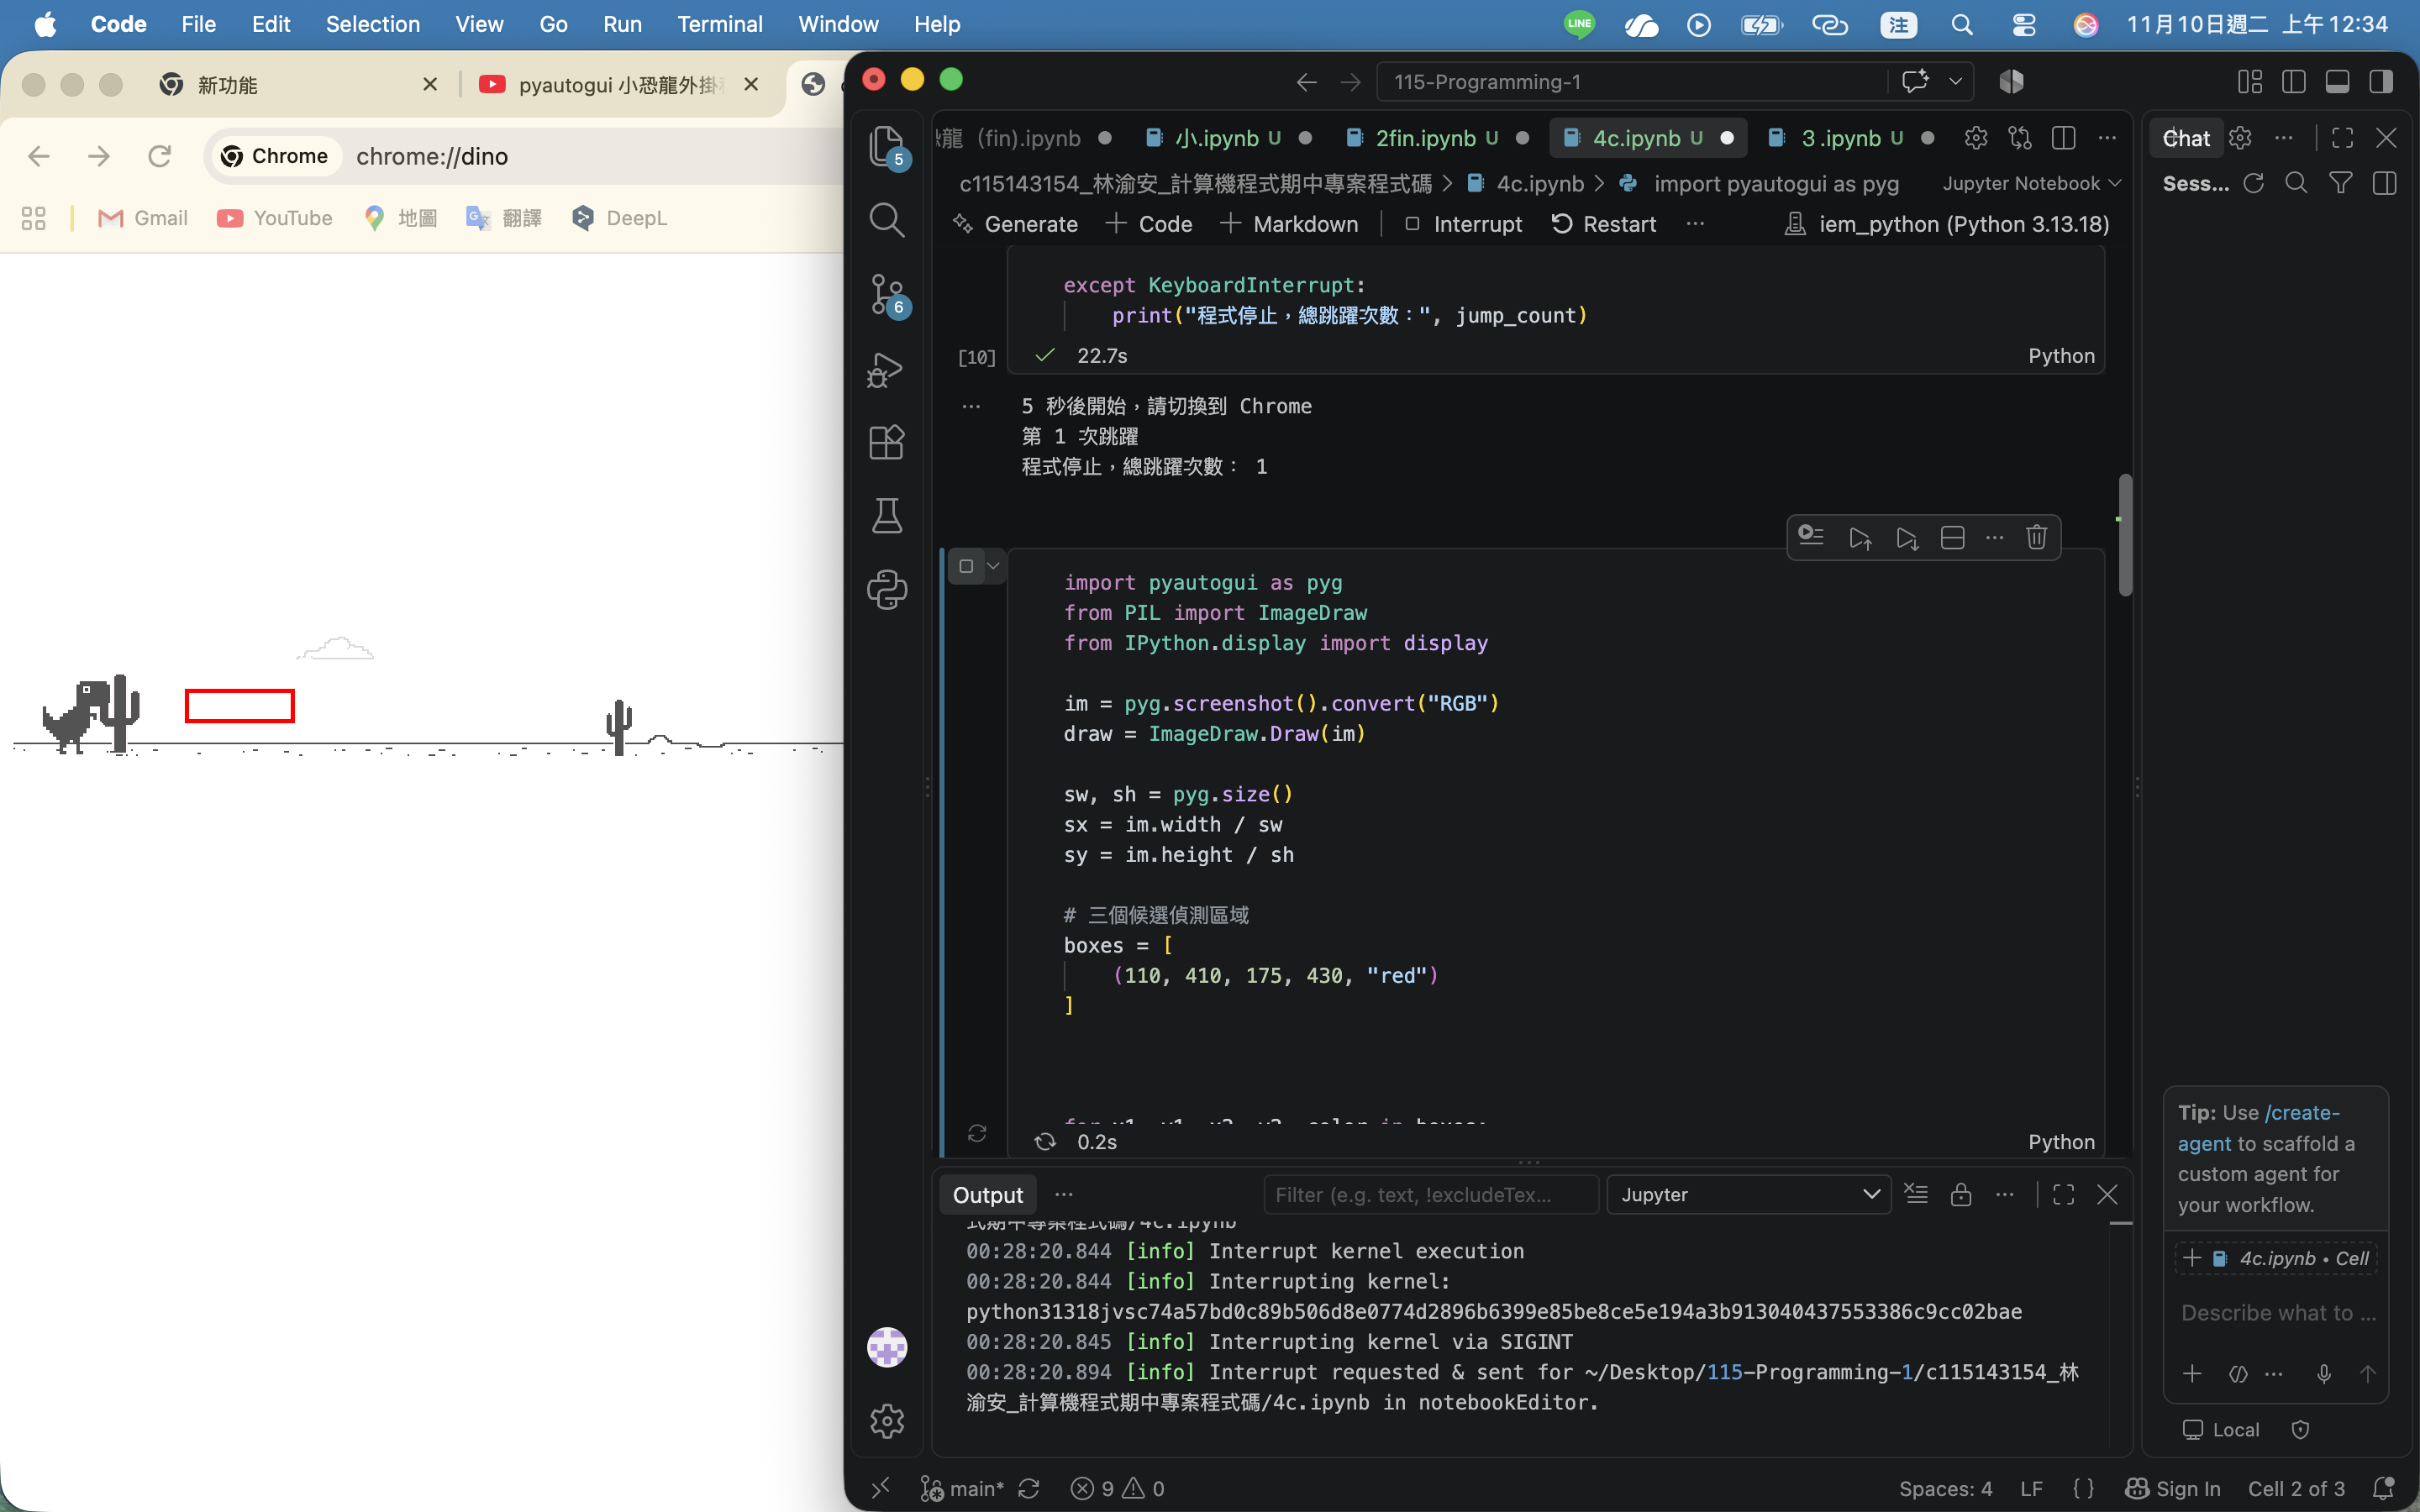

In [12]:
import pyautogui as pyg
from PIL import ImageDraw
from IPython.display import display

im = pyg.screenshot().convert("RGB")
draw = ImageDraw.Draw(im)

sw, sh = pyg.size()
sx = im.width / sw
sy = im.height / sh

# 三個候選偵測區域
boxes = [
    (110, 410, 175, 430, "red")
]



for x1, y1, x2, y2, color in boxes:
    draw.rectangle(
        (
            int(x1 * sx),
            int(y1 * sy),
            int(x2 * sx),
            int(y2 * sy)
        ),
        outline=color,
        width=5
    )

display(im)

In [65]:
import time
import pyautogui as pyg

pyg.FAILSAFE = True

# 根據藍框調整
START_X = 110
END_X = 175
TOP_Y = 410
BOTTOM_Y = 430

# Retina 比例
sw, sh = pyg.size()
shot = pyg.screenshot()
sx = shot.width / sw
sy = shot.height / sh

box = (
    int(START_X * sx),
    int(TOP_Y * sy),
    int(END_X * sx),
    int(BOTTOM_Y * sy)
)

print("5 秒後開始，請切換到 Chrome")
time.sleep(5)

# 自動開始遊戲
pyg.press("space")
time.sleep(0.4)

last_jump = 0
was_found = False
jump_count = 0

try:
    while True:
        im = pyg.screenshot()
        region = im.crop(box).convert("RGB")

        # 計算深色像素數量
        dark_count = 0

        for x in range(0, region.width, 4):
            for y in range(0, region.height, 4):
                r, g, b = region.getpixel((x, y))

                if max(r, g, b) < 120:
                    dark_count += 1

        found = dark_count >= 5
        now = time.time()

        if found and not was_found and now - last_jump > 0.35:
            pyg.press("space")
            last_jump = now
            jump_count += 1
            print("第", jump_count, "次跳躍")

        was_found = found

        time.sleep(0.005)

except KeyboardInterrupt:
    print("程式停止，跳躍次數：", jump_count)

5 秒後開始，請切換到 Chrome
第 1 次跳躍
程式停止，跳躍次數： 1


In [64]:
import time
import pyautogui as pyg

# 設定滑鼠移到螢幕左上角可以緊急停止
pyg.FAILSAFE = True

# 減少 PyAutoGUI 執行指令時的額外等待
pyg.PAUSE = 0

# 取得螢幕與截圖大小
screen_width, screen_height = pyg.size()
im = pyg.screenshot()

# 計算 Mac Retina 螢幕縮放比例
scale_x = im.width / screen_width
scale_y = im.height / screen_height

# 偵測位置（MouseInfo 原始座標）
start_x = 110
start_y = 420

# 掃描寬度
scan_width = 60

# 設定上次跳躍時間
last_jump = 0

print("小恐龍自動遊玩準備中...")
print("請在 5 秒內切換到 Chrome 遊戲畫面！")

time.sleep(5)

# 自動按空白鍵開始遊戲
pyg.press("space")

print("遊戲開始！")

try:
    # 無窮迴圈，不斷監視畫面
    while True:

        # 擷取螢幕畫面
        im = pyg.screenshot()

        # 先假設沒有仙人掌
        obs = False

        # 掃描恐龍前方的水平區域
        for i in range(scan_width):

            # 將 MouseInfo 座標換算成截圖像素
            x = int((start_x + i) * scale_x)
            y = int(start_y * scale_y)

            # 讀取指定位置的 RGB 顏色
            c = im.getpixel((x, y))[:3]

            # 判斷是否出現仙人掌的深灰色
            # 允許小幅色差，避免完全相等造成漏判
            if all(abs(c[j] - 83) <= 15 for j in range(3)):
                obs = True
                break

        # 如果偵測到仙人掌，就按空白鍵跳躍
        if obs and time.time() - last_jump > 0.35:

            pyg.press("space")

            # 更新上次跳躍時間
            last_jump = time.time()

            print("偵測到仙人掌，跳躍！")

except KeyboardInterrupt:
    print("程式已停止")


小恐龍自動遊玩準備中...
請在 5 秒內切換到 Chrome 遊戲畫面！
遊戲開始！
程式已停止
